---
title: "Chapter 20: Survival analysis"
---

::: {.callout-lo}
## Learning outcomes {.unnumbered}

By the end of this chapter, you should be able to:

- Recognize time-to-event problems with incomplete observation and explain why ordinary classification or regression may be unsuitable.
- Represent an outcome using observed duration and an event indicator.
- Use `lifelines` to fit Kaplan–Meier curves and a Cox model.
- Interpret survival curves, group comparisons, coefficient signs, and predicted retention probabilities.
- Explain important limitations when evaluating predictions and using them to make decisions.
:::

**Imports**

This chapter uses `lifelines` alongside our familiar Python tools. If needed, install it in the environment used to run this notebook:

```bash
python -m pip install lifelines
```

In [2]:
#| code-fold: true
#| code-summary: "Show imports and setup"
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.plotting import add_at_risk_counts
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder

plt.rcParams["font.size"] = 12
DATA_DIR = Path("data") if Path("data").is_dir() else Path("book") / "data"
DATA_PATH = DATA_DIR / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
RANDOM_STATE = 123

## Why we need survival analysis

Imagine you work for a subscription-based telecom company. Your team wants to anticipate when customers might leave so that it can plan retention efforts. A prediction of when a customer will leave could help decide when to contact them, although it would not tell us whether a particular promotion would persuade them to stay.

You already know classification and regression. We could classify customers as likely to churn, or use regression to predict the number of months until they leave. Before choosing a model, though, we need to ask: **what target values do we actually have?**

Suppose our records contain these three customers. We measure time from each customer's signup.

| Customer | Observed duration | Churn observed? | What we know about time to churn |
|---|---:|---|---|
| A | 4 months | Yes | They churned at month 4. |
| B | 4 months | No | They stayed beyond month 4; their final duration is unknown. |
| C | 18 months | No | They stayed beyond month 18; their final duration is unknown. |

A and B have the same observed duration, but very different outcomes. For A, four months is a completed subscription. For B, it is only the duration observed so far.

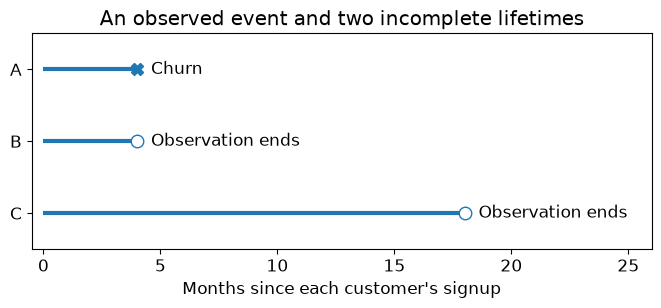

In [3]:
fig, ax = plt.subplots(figsize=(8, 2.8))
for y, (customer, duration, observed) in enumerate(
    [("A", 4, True), ("B", 4, False), ("C", 18, False)]
):
    ax.hlines(y, 0, duration, color="tab:blue", linewidth=3)
    ax.plot(duration, y, "X" if observed else "o", color="tab:blue",
            markerfacecolor="tab:blue" if observed else "white", markersize=9)
    ax.text(duration + 0.6, y, "Churn" if observed else "Observation ends", va="center")
ax.set(yticks=[0, 1, 2], yticklabels=["A", "B", "C"],
       xlabel="Months since each customer's signup", xlim=(-0.5, 26), ylim=(-0.5, 2.5))
ax.invert_yaxis()
ax.set_title("An observed event and two incomplete lifetimes")
plt.show()

The open circles mark the end of observation, not churn. These timelines align customers by time since signup; they need not have joined on the same calendar date.

B and C are **right-censored**: we stopped observing them before observing the event. Their durations give us lower bounds on their time to churn. Censoring does not mean that a customer will never leave, and it does not erase what we already know about their subscription.

This is the gap in our current toolbox. An ordinary regressor expects an exact numerical target for every training example. Here, some targets are exact event times and others are bounds. We need an approach that can learn from both.

Although the name **survival analysis** comes from studying lifetimes, its methods apply to time until many kinds of events: equipment failure, finding a job, or leaving a subscription service. We must define both the event and the time origin. Here they are churn and signup, respectively.

### What about classification?

Suppose we collect a snapshot of customer records, with a `Churn` column indicating whether churn has been observed. A classifier trained on this column learns to distinguish customers recorded as having churned from those recorded as active. That is different from predicting their eventual subscription length. In particular, an active customer observed for two months has had much less opportunity to churn than one observed for two years.

Classification can still answer a useful question such as “Will this customer churn within six months of signup?” But we need labels for that specific horizon. A customer who churned at month 4 has a known positive label; a customer still active at month 8 has a known negative label. For a customer whose observation ends at month 2 without churn, the six-month label is unknown. Labelling that customer negative would be a mistake.

To answer questions about timing, we need to retain how long each customer was observed and whether churn occurred. Before fitting a model, let’s consider two tempting ways to turn these outcomes into regression targets.

### Two tempting shortcuts

**Use only customers who churned.** We know their completed subscription lengths, so we could discard the other rows and fit a regressor. But customers with longer subscriptions have more opportunity to remain active when observation ends. Discarding them loses evidence of longer subscriptions and can make lifetimes look shorter than they really are.

**Treat every observed tenure as a completed lifetime.** This keeps all the rows, but treats active customers as if they churned when observation ended. We would be learning how long customers were observed, rather than how long they stayed before leaving.

Changing regressors or tuning hyperparameters does not fix the meaning of these targets. We need an approach that uses both completed subscriptions and what we know about incomplete ones.

### Exercise 20.1: What information are we throwing away?

A customer is still subscribed when observation ends at month 15.

1. What do we know about their time to churn? What do we not know?
2. What mistake would each shortcut make with this record?
3. Why would replacing their unknown churn time with the mean tenure of customers who churned lose useful information?

## Preparing the customer data

To explore this problem, we will use the [Telco Customer Churn dataset](https://www.kaggle.com/datasets/blastchar/telco-customer-churn). For this teaching example, we interpret `tenure` as the number of months from signup to churn or the end of observation, and `Churn` as the indicator that churn was observed.

::: {.callout-note title="What this dataset can establish"}
The table is a snapshot, rather than a documented longitudinal record of every customer's history. Our interpretation of duration, event status, and follow-up is a teaching assumption. Before using these methods operationally, we would verify how customers were sampled, how churn and follow-up were recorded, and which features were available at prediction time.

In particular, current contract and billing information need not be the information available at signup. We will use these attributes to demonstrate the models, but the resulting predictions are not a validated deployment workflow.
:::

As usual, we reserve a test set before fitting models or preprocessing.

In [4]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Download the Telco CSV and place it at {DATA_PATH.resolve()}")
raw = pd.read_csv(DATA_PATH)
train_raw, test_raw = train_test_split(
    raw, test_size=0.25, random_state=RANDOM_STATE, stratify=raw["Churn"]
)
display(train_raw.head())
train_raw.info()
display(train_raw.isna().sum().rename("missing values"))

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
1487,5035-PGZXH,Female,0,No,No,56,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Electronic check,106.80,5914.4,No
1485,9809-IMGCQ,Male,1,No,No,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,96.70,2082.95,Yes
4731,8748-HFWBO,Male,0,Yes,Yes,19,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,19.90,357.7,No
5987,1099-GODLO,Female,0,Yes,Yes,1,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.35,20.35,No
5058,1376-HHBDV,Female,0,No,No,30,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,48.80,1536.75,No


<class 'pandas.DataFrame'>
Index: 5282 entries, 1487 to 5298
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5282 non-null   str    
 1   gender            5282 non-null   str    
 2   SeniorCitizen     5282 non-null   int64  
 3   Partner           5282 non-null   str    
 4   Dependents        5282 non-null   str    
 5   tenure            5282 non-null   int64  
 6   PhoneService      5282 non-null   str    
 7   MultipleLines     5282 non-null   str    
 8   InternetService   5282 non-null   str    
 9   OnlineSecurity    5282 non-null   str    
 10  OnlineBackup      5282 non-null   str    
 11  DeviceProtection  5282 non-null   str    
 12  TechSupport       5282 non-null   str    
 13  StreamingTV       5282 non-null   str    
 14  StreamingMovies   5282 non-null   str    
 15  Contract          5282 non-null   str    
 16  PaperlessBilling  5282 non-null   str    
 17  PaymentM

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
Name: missing values, dtype: int64

One row represents a customer. `tenure` records their observed duration, and `Churn` tells us whether that duration ended in an observed departure.

The missing-value counts suggest that nothing is missing. But why is `TotalCharges` stored as text? Before converting a column, it helps to inspect the values that prevent conversion.

In [5]:
# Catch the conversion error so running the whole notebook remains possible.
try:
    train_raw["TotalCharges"].astype(float)
except ValueError as error:
    print(error)

# Ordinary printing can hide a blank string; repr makes whitespace visible.
charges_text = train_raw["TotalCharges"].astype("string")
blank_charges = charges_text.str.strip().eq("")
display(charges_text.loc[blank_charges].map(repr).rename("visible representation"))
display(train_raw.loc[blank_charges, ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

could not convert string to float: ' '


1082    ' '
6754    ' '
1340    ' '
5218    ' '
488     ' '
4380    ' '
6670    ' '
753     ' '
Name: visible representation, dtype: str

,tenure,MonthlyCharges,TotalCharges,Churn
1082,0,25.75,,No
6754,0,61.90,,No
1340,0,56.05,,No
5218,0,19.70,,No
488,0,52.55,,No
4380,0,20.00,,No
6670,0,73.35,,No
753,0,20.25,,No


Whitespace is still a string value, so `isna()` does not count it as missing. Using `repr` makes those spaces visible. Inspect the affected rows before deciding what they mean: zero tenure might suggest that no bill has accumulated yet, but that is a hypothesis to check rather than a reason to fill every missing charge with zero.

We strip the whitespace, mark empty strings as missing, and convert the remaining values to numbers. We also create the **event indicator** expected by `lifelines`:

- **1:** churn was observed; the duration ends with departure.
- **0:** churn was not observed; the duration is follow-up so far.

Zero means “event not observed,” not “this customer will never churn.” Together, `tenure` and `event` describe the outcome.

In [6]:
def clean_customers(frame):
    cleaned = frame.copy()
    # Strip whitespace, mark empty strings as missing, then require numeric values.
    charges = cleaned["TotalCharges"].astype("string").str.strip().replace("", pd.NA)
    cleaned["TotalCharges"] = pd.to_numeric(charges, errors="raise")
    # lifelines needs to know whether the event was observed (1) or censored (0).
    cleaned["event"] = cleaned["Churn"].map({"Yes": 1, "No": 0})
    assert cleaned["event"].notna().all(), "Unexpected Churn label"
    assert cleaned["tenure"].notna().all() and cleaned["tenure"].ge(0).all()
    return cleaned

train = clean_customers(train_raw)
test = clean_customers(test_raw)
display(train[["TotalCharges", "tenure", "event"]].dtypes)
display(train["TotalCharges"].isna().value_counts().rename("customers"))

TotalCharges    Float64
tenure            int64
event             int64
dtype: object

TotalCharges
False    5274
True        8
Name: customers, dtype: int64

After all this preprocessing, **we are going to exclude `TotalCharges` from our survival model!** Why?

We want to model time **from joining to churn**, but `TotalCharges` grows as a customer stays. The recorded total is from the end of their observed time, not from signup. It therefore contains information accumulated during the very period we are trying to model. A large total may simply tell us that the customer has already stayed a long time.

Cleaning the column was still useful: it showed us how whitespace can hide missing values. But a clean column is not automatically a suitable predictor. Since we exclude `TotalCharges`, we do not need to fill its missing values for this model.

We also exclude `customerID`. We keep `tenure` and `event` to tell `lifelines` how long each customer was observed and whether they churned; these are not predictors.

Could `TotalCharges` ever be useful for predicting churn? Yes: at a defined prediction time, such as month 12, charges accumulated **up to that time** could help predict subsequent churn. That requires a different data setup, with features recorded before the future outcome.

## Estimating overall retention with Kaplan–Meier

Before using customer features, let’s ask about customers as a group: **what proportion remain subscribed beyond a given duration?** A **survival curve** describes this probability across time. Here, “survival” simply means remaining with the service.

For example, a curve with a value of 0.8 at month 12 estimates an 80% probability of staying beyond 12 months from signup. It does not mean that 80% of customers active today will stay another 12 months: those customers have already stayed for different lengths of time.

Without censoring, we could count how many customers lasted beyond each month. With censoring, some later outcomes are unknown. The **Kaplan–Meier estimator** uses customers for as long as we observe them, without treating the end of observation as churn.

### How a censored customer contributes

Suppose four customers have these outcomes:

| Customer | Observed duration (months) | Event observed |
|---|---:|---:|
| A | 2 | 1 |
| B | 3 | 0 |
| C | 4 | 1 |
| D | 5 | 0 |

At month 2, all four customers are still being observed immediately before A churns. Three of the four remain, so the estimate drops from 100% to 75%.

At month 3, observation ends for B. There is no observed churn, so the curve stays at 75%. B contributes information up to this point, but cannot tell us what happens later.

At month 4, only C and D are still being observed. C churns, so half of those two remain. Kaplan–Meier keeps half of the previous 75% estimate, bringing the curve to 37.5%.

The package calls the customers still observed and not yet churned **“at risk.”** This means they could still experience the event; it does not mean that a model has classified them as high-risk customers.

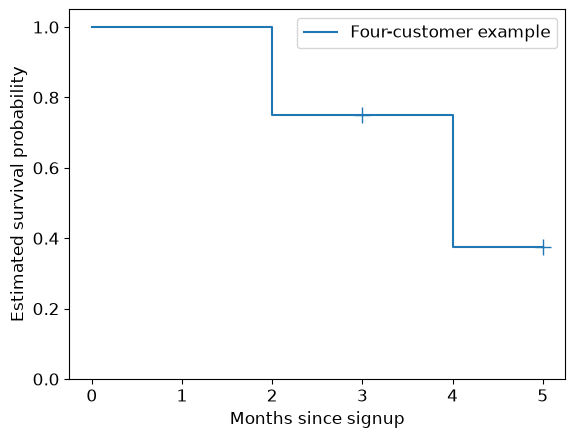

In [7]:
small = pd.DataFrame({"duration": [2, 3, 4, 5], "event": [1, 0, 1, 0]})
small_km = KaplanMeierFitter(label="Four-customer example")
small_km.fit(small["duration"], event_observed=small["event"])
ax = small_km.plot_survival_function(ci_show=False, show_censors=True)
ax.set(xlabel="Months since signup", ylabel="Estimated survival probability", ylim=(0, 1.05))
plt.show()

The curve drops at an observed churn, while censor marks indicate observation ending without churn. Censoring changes who can contribute to later estimates, but does not itself make the curve drop.

After month 5, nobody remains under observation. A flat tail does not establish that the remaining customers will never churn; we have run out of follow-up.

### Fitting the telecom curve

Kaplan–Meier uses only durations and event indicators. It needs neither one-hot encoding nor scaling. Pass the durations to `fit` and the event indicator to `event_observed`. The fitted object can plot the curve and return estimated survival probabilities at chosen months.

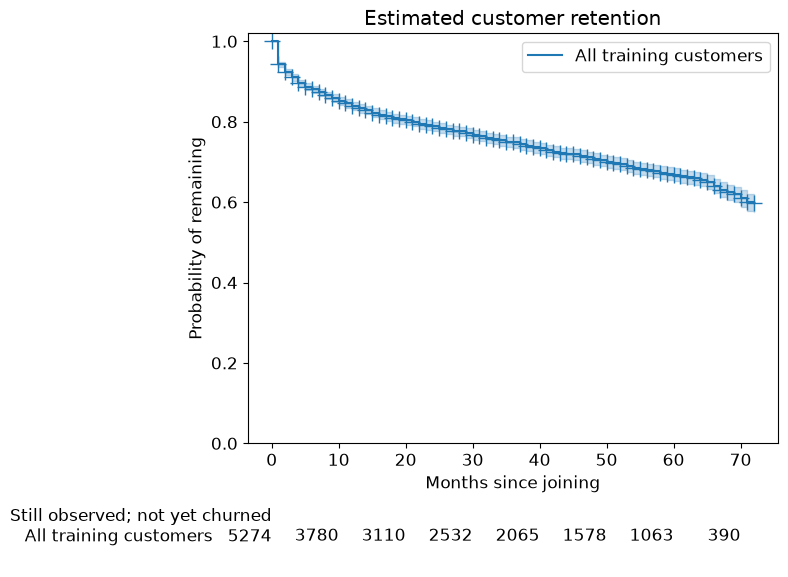

12    0.839878
24    0.788243
Name: estimated survival, dtype: float64

In [8]:
km_all = KaplanMeierFitter(label="All training customers")
km_all.fit(train["tenure"], event_observed=train["event"])
fig, ax = plt.subplots(figsize=(8, 6))
km_all.plot_survival_function(ax=ax, show_censors=True)
ax.set(title="Estimated customer retention", xlabel="Months since joining",
       ylabel="Probability of remaining", ylim=(0, 1.02))
add_at_risk_counts(km_all, ax=ax, rows_to_show=["At risk"])
# Replace the package’s statistical label with a plain-language description.
count_ax = fig.axes[-1]
count_ax.set_xticklabels([
    label.get_text().replace("At risk", "Still observed; not yet churned")
    for label in count_ax.get_xticklabels()
])
plt.tight_layout()
plt.show()
display(km_all.survival_function_at_times([12, 24]).rename("estimated survival"))

At month 12, read the height of the curve as the estimated probability of remaining subscribed beyond 12 months from signup. A steeper decline indicates more estimated loss of customers over that period.

The curve is estimated from the customers we observed. A different sample would give a somewhat different curve. The **shaded band shows uncertainty in the estimate**: a wider band means a less precise estimate. It does not show the range of times when individual customers will leave. The package calls these bands *confidence intervals*; we will focus on their visual interpretation here.

The row below the plot counts customers still observed and not yet churned. A customer whose observation ended at month 8 is no longer counted at month 12, even if they had not churned. Near the right-hand tail, fewer observations support the curve, so avoid strong conclusions from small differences.

There is an important assumption here: customers whose observations end should have similar future retention to those still observed. Ending data collection on a fixed date may make this reasonable. Losing track specifically of customers who are about to leave would make it questionable. Survival analysis handles incomplete follow-up under assumptions; it does not automatically repair a biased observation process.

### Exercise 20.2: Read the curve

Return to the four-customer example.

1. Why does the curve stay flat at month 3 even though one customer leaves observation?
2. If B had instead churned at month 3, would the curve drop? Who would contribute to that update?
3. Why does the final flat stretch not mean that the remaining customers will never churn?

## Comparing contract groups

The overall curve combines customers with different plans and circumstances. Do customers on different contracts show different retention patterns? We can fit a separate Kaplan–Meier curve for each contract group.

Before running the code, predict which group will have the highest retention. Would a difference necessarily be caused by the contract?

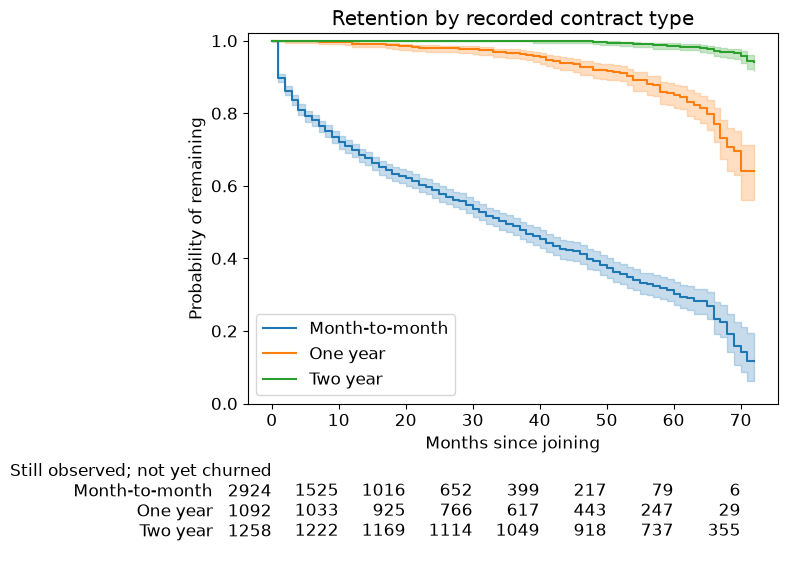

,Customers,Observed churns,12-month retention,24-month retention
Contract,,,,
Month-to-month,2924,1251,0.699,0.588
One year,1093,117,0.991,0.980
Two year,1265,34,1.000,1.000


In [9]:
contract_order = ["Month-to-month", "One year", "Two year"]
fig, ax = plt.subplots(figsize=(8, 6))
contract_fitters = []
contract_summary = []
for contract in contract_order:
    group = train.loc[train["Contract"].eq(contract)]
    km = KaplanMeierFitter(label=contract)
    km.fit(group["tenure"], event_observed=group["event"])
    km.plot_survival_function(ax=ax)
    contract_fitters.append(km)
    contract_summary.append({
        "Contract": contract, "Customers": len(group), "Observed churns": group["event"].sum(),
        "12-month retention": km.predict(12), "24-month retention": km.predict(24),
    })
ax.set(title="Retention by recorded contract type", xlabel="Months since joining",
       ylabel="Probability of remaining", ylim=(0, 1.02))
add_at_risk_counts(*contract_fitters, ax=ax, rows_to_show=["At risk"])
# Replace the package’s statistical label with a plain-language description.
count_ax = fig.axes[-1]
count_ax.set_xticklabels([
    label.get_text().replace("At risk", "Still observed; not yet churned")
    for label in count_ax.get_xticklabels()
])
plt.tight_layout()
plt.show()
display(pd.DataFrame(contract_summary).set_index("Contract").round(3))

The table summarizes group sizes, observed departures, and estimated retention at 12 and 24 months. Read those retention values as probabilities from signup, under our interpretation of these snapshot records.

These curves compare groups as they are. Customers choose contracts and may also differ in price, service needs, satisfaction, and other characteristics. We also do not observe their contract histories. The curves do not tell us what would happen if we changed someone's contract.

A difference can suggest a useful question to investigate. For example, the company could test a voluntary contract offer and measure both retention and business costs. The group curves alone do not establish that the offer will work.

## Using several features with a Cox model

Comparing contracts one at a time leaves other customer differences mixed together. Can we relate several features to retention at once?

The **Cox proportional hazards model**, available through `CoxPHFitter`, does this while accounting for censoring. We will focus on fitting it, reading coefficient directions, and interpreting predicted survival curves.

For the coefficients, a **positive value** is associated with faster churn and a **negative value** with slower churn, holding the other included features fixed. These values are not changes in churn probability or numbers of months.

The model's name refers to how it represents the rate of churn among customers who have stayed until a given time. It assumes that a feature multiplies that rate by the same amount throughout follow-up. For example, a contract whose association with churn reverses around renewal would challenge this assumption. The model can fit successfully even when this assumption is unsuitable.

### Preparing the predictors

We use contract, internet service, monthly charges, and senior status, matching the class demo. Monthly charges are divided by 10, so one unit means **$10 per month**. This changes the units, not the information in the feature.

For categorical features, we explicitly choose **one-year contracts** and **DSL** as comparison groups. With `drop="first"`, the encoder omits an indicator for each comparison group. A one-year contract is still represented: both the month-to-month and two-year indicators are zero.

Fit the preprocessor on training predictors only, then reuse it for test customers and new profiles. The duration and event indicator bypass preprocessing because they describe the outcome, not the inputs.

In [10]:
numeric_features = ["MonthlyCharges"]
categorical_features = ["Contract", "InternetService"]
passthrough_features = ["SeniorCitizen"]
raw_predictor_columns = numeric_features + categorical_features + passthrough_features

# A $10 increase becomes a one-unit increase; retain an informative column name.
def dollars_to_tens(values):
    return values / 10


def charge_feature_names(transformer, input_features):
    return ["MonthlyCharges10"]


preprocessor = ColumnTransformer(
    transformers=[
        ("charges", FunctionTransformer(
            dollars_to_tens, feature_names_out=charge_feature_names
        ), numeric_features),
        ("categorical", OneHotEncoder(
            categories=[["One year", "Month-to-month", "Two year"], ["DSL", "Fiber optic", "No"]],
            drop="first", sparse_output=False,
        ), categorical_features),
        ("passthrough", "passthrough", passthrough_features),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

X_train = preprocessor.fit_transform(train[raw_predictor_columns])
X_test = preprocessor.transform(test[raw_predictor_columns])
predictor_columns = X_train.columns.tolist()
display(X_train.head())

,MonthlyCharges10,Contract_Month-to-month,Contract_Two year,InternetService_Fiber optic,InternetService_No,SeniorCitizen
1487,10.680,0.0,0.0,1.0,0.0,0
1485,9.670,1.0,0.0,1.0,0.0,1
4731,1.990,0.0,0.0,0.0,1.0,0
5987,2.035,0.0,1.0,0.0,1.0,0
5058,4.880,1.0,0.0,0.0,0.0,0


### Fitting and reading the model

Unlike a scikit-learn regressor with one target, `lifelines` accepts a DataFrame containing the predictors and both outcome columns. After transforming the predictors, we join the outcomes by row index and tell `fit` which columns contain duration and event status.

We use a small L2 penalty, similar to ridge regression, to keep coefficients from becoming too large. This is a fixed teaching choice rather than a value chosen using test performance. Regularization does not fix unsuitable predictors or model assumptions.

In [11]:
# Outcomes bypass preprocessing; preserving row indices keeps them aligned.
train_surv = X_train.join(train[["tenure", "event"]])
test_surv = X_test.join(test[["tenure", "event"]])
assert not train_surv.isna().any().any(), "Inspect missing model inputs before fitting"
cph = CoxPHFitter(penalizer=0.01, l1_ratio=0.0)
cph.fit(train_surv, duration_col="tenure", event_col="event")
coefficients = cph.params_.sort_values(ascending=False).rename("Coefficient")
display(coefficients.to_frame().round(3))

,Coefficient
covariate,
Contract_Month-to-month,1.903
InternetService_Fiber optic,1.186
SeniorCitizen,-0.002
MonthlyCharges10,-0.227
InternetService_No,-0.975
Contract_Two year,-1.510


Read a categorical coefficient relative to its omitted group. For example, the month-to-month coefficient compares month-to-month with one-year contracts while holding the other included features fixed. The monthly-charge coefficient describes a $10 increase, again holding those features fixed.

The table is sorted to make directions easier to scan. It is **not a feature-importance ranking**: the features have different units and comparisons. A coefficient near zero describes little difference according to this fitted model; it does not prove that the feature never matters.

These comparisons can differ from the separate group curves because the model considers several features together. Unrecorded features and changes during follow-up can still affect the results. Neither the coefficients nor the group curves establish what would happen if we changed a customer's plan.

If you inspect the full `cph.summary`, you will also see `exp(coef)`, labelled a *hazard ratio*. It expresses the same direction on another scale: above 1 corresponds to faster churn, below 1 to slower churn. It is not a churn probability or a change in lifetime. The compact coefficient table and predicted survival curves are enough for our walkthrough.

## Interpreting predicted retention curves

The retention team needs probabilities at useful times, rather than just coefficient signs. `predict_survival_function` returns a survival curve for each supplied feature profile.

To make the comparison easy to read, take one training customer's features and create three profiles that differ only in contract. These are model-based comparisons, not estimates of the effect of changing that customer's contract. We pass the raw profiles through the same training-fitted preprocessor before predicting.

,MonthlyCharges,Contract,InternetService,SeniorCitizen
Contract scenario,,,,
Month-to-month,106.8,Month-to-month,Fiber optic,0
One year,106.8,One year,Fiber optic,0
Two year,106.8,Two year,Fiber optic,0


,MonthlyCharges10,Contract_Month-to-month,Contract_Two year,InternetService_Fiber optic,InternetService_No,SeniorCitizen
Contract scenario,,,,,,
Month-to-month,10.68,1.0,0.0,1.0,0.0,0
One year,10.68,0.0,0.0,1.0,0.0,0
Two year,10.68,0.0,1.0,1.0,0.0,0


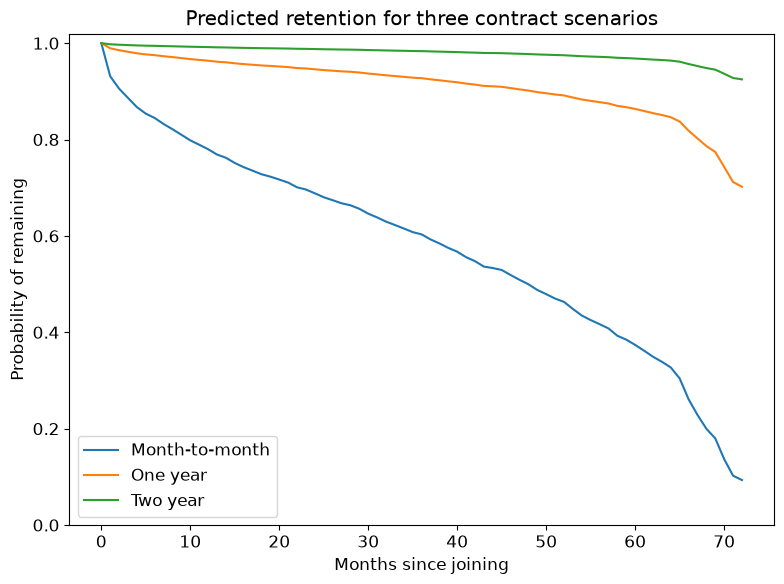

,12-month retention,24-month retention
Month-to-month,0.780,0.688
One year,0.964,0.946
Two year,0.992,0.988


In [12]:
raw_profiles = pd.concat([train[raw_predictor_columns].iloc[[0]]] * 3, ignore_index=True)
raw_profiles["Contract"] = contract_order
raw_profiles.index = pd.Index(contract_order, name="Contract scenario")
display(raw_profiles)
# Reuse the training-fitted preprocessor; do not fit on these new profiles.
profiles = preprocessor.transform(raw_profiles)
profiles.index = pd.Index(contract_order, name="Contract scenario")
display(profiles)
curves = cph.predict_survival_function(profiles)
ax = curves.plot(figsize=(8, 6))
ax.set(title="Predicted retention for three contract scenarios", xlabel="Months since joining",
       ylabel="Probability of remaining", ylim=(0, 1.02))
plt.tight_layout()
plt.show()
display(cph.predict_survival_function(profiles, times=[12, 24]).T.rename(columns={12: "12-month retention", 24: "24-month retention"}).round(3))

Each curve starts at signup. At month 12, its height gives the predicted probability of remaining subscribed beyond that month for that profile. The table makes the 12- and 24-month comparisons easier to read. A lower curve means a higher predicted chance of having churned by that time.

The curves summarize uncertainty about **when churn occurs** across customers with those features; they do not promise a departure month for a particular person. They also differ from uncertainty bands around an estimated curve: a predicted survival probability and uncertainty about that estimated probability are different ideas.

### Exercise 20.3: Explain the model output

1. A contract coefficient is negative relative to the one-year comparison group. What does its sign tell us? Does it give a decrease in churn probability?
2. Where in the output would you find a predicted probability of staying beyond 12 months?
3. Would these results justify moving every customer to a two-year contract? What additional evidence would you want?

### Signup versus months from today

A curve measured from signup is not automatically a forecast of months from today for an existing customer. Someone who has already stayed for 20 months has already passed through the first 20 months of the curve. Their question is: **“Given that they stayed this long, how likely are they to stay another 12 months?”**

For example, imagine 100 comparable customers, of whom 80 remain at month 20 and 60 remain at month 32. Among the 80 who reached month 20, 60 stayed for the additional 12 months: 75%. We need to focus on those who reached the current tenure, rather than reading the curve at month 12 from signup.

`lifelines` provides `conditional_after` for this purpose. The optional example below shows how to use it. We begin with probabilities over supported time horizons rather than asking for one exact departure time. A model cannot establish what happens beyond the available follow-up without further assumptions.

## Evaluating predictions and deciding what to do

As with our earlier models, we need to check predictions on held-out data. Ordinary regression error cannot directly compare a predicted departure time with every recorded tenure: for censored customers, tenure is not their final subscription length.

The **concordance index**, or **c-index**, checks whether the model tends to rank earlier departures as higher churn risk. It uses customer pairs whose order can be determined. If A churns at month 4 and B is observed without churn through month 10, A left first. If A is censored at month 4 and B churns at month 10, we do not know whose eventual departure is earlier.

A score around 0.5 means chance-level ranking; 1 means all compared pairs are ordered correctly. This is a ranking measure, not the fraction of customers whose departure month was predicted correctly. Good ranking also does not guarantee accurate retention probabilities.

We evaluate the fixed model once on the reserved test set. If the results guide further model changes, we would need fresh data for final evaluation.

In [13]:
print(f"Training concordance: {cph.concordance_index_:.3f}")
print(f"Test concordance: {cph.score(test_surv, scoring_method='concordance_index'):.3f}")

Training concordance: 0.828
Test concordance: 0.817


This random split checks performance for customers sampled in a similar way to this snapshot. Before deployment, we would also need to check predictions on appropriate future data, with features recorded at the intended prediction time. We would check whether predicted retention probabilities match observed retention using methods that account for censoring; the c-index alone does not answer that question.

With a limited retention budget, predicted churn risk is only part of the decision. We also need the likely benefit of the proposed action, contact costs, and customer value. A high-risk customer is not necessarily someone whose behavior an offer can change. Predictions can help us decide what to test; an experiment can help establish whether the action improves retention.

## Optional: predicting remaining retention for an active customer

Here we select an active training customer and supply their tenure to `conditional_after`. The new horizontal axis measures **months into the future**, after their observed tenure. We limit it so the customer's tenure plus the forecast horizon stays within the training data's observed duration range. Even within that range, estimates near the tail may have little supporting follow-up.

Customer has already remained for 56 months.


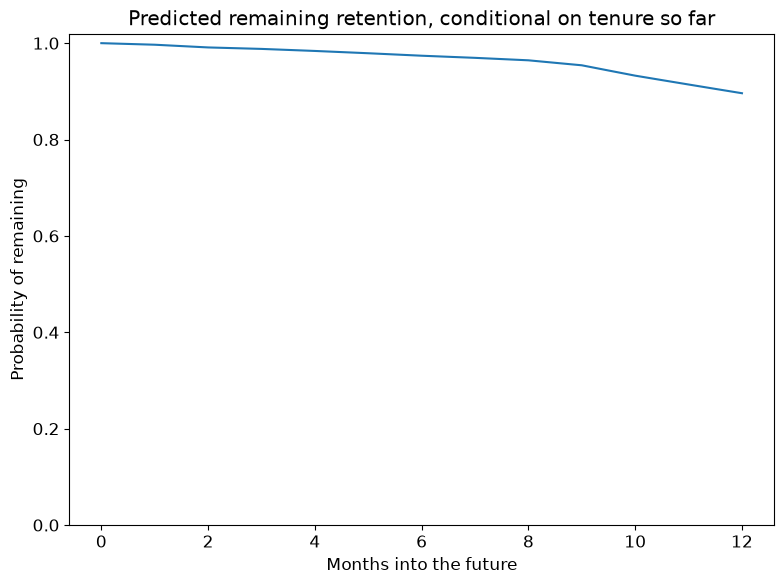

In [14]:
active = train_surv.loc[train_surv["event"].eq(0)].iloc[[0]]
current_tenure = float(active["tenure"].iloc[0])
remaining_horizon = min(12, float(train_surv["tenure"].max()) - current_tenure)
print(f"Customer has already remained for {current_tenure:g} months.")
if remaining_horizon > 0:
    future_times = np.linspace(0, remaining_horizon, 25)
    conditional = cph.predict_survival_function(
        active[predictor_columns], times=future_times, conditional_after=[current_tenure]
    )
    ax = conditional.plot(figsize=(8, 6), legend=False)
    ax.set(title="Predicted remaining retention, conditional on tenure so far",
           xlabel="Months into the future", ylabel="Probability of remaining", ylim=(0, 1.02))
    plt.tight_layout()
    plt.show()
else:
    print("No additional follow-up horizon is supported for this customer.")

## Summary

- **Right-censored outcomes contain partial information.** We know how long a customer stayed under observation, but not their eventual departure time. Dropping the record or pretending observation ended in churn loses that distinction.
- **Represent outcomes with duration and event status.** `lifelines` uses both pieces of information to distinguish observed departures from incomplete follow-up.
- **Use Kaplan–Meier to estimate retention.** It produces an overall survival curve or separate group curves without using other predictors.
- **Use Cox regression to incorporate several features.** Coefficient signs describe faster or slower churn, holding the other included features fixed. Predicted survival curves give retention probabilities at useful times.
- **Read curves with their time origin in mind.** “Beyond 12 months from signup” differs from “another 12 months for an existing customer.”
- **Interpret results with care.** Pay attention to uncertainty, the number still observed, feature availability, and model assumptions. Group differences and model predictions describe associations; they do not establish the benefit of a retention intervention.
- **Choose the approach to match the question and observations.** Use survival analysis when timing matters and some event times are incompletely observed. Classification may be simpler for a single fixed-horizon decision when everyone has enough follow-up to label that horizon. Ordinary regression may be reasonable when every event time is known exactly. A time column alone does not determine which approach to use.

**Further reading**

- [Telco Customer Churn dataset](https://www.kaggle.com/datasets/blastchar/telco-customer-churn).
- [Kaplan–Meier estimation in lifelines](https://lifelines.readthedocs.io/en/latest/Survival%20analysis%20with%20lifelines.html).
- [Survival regression in lifelines](https://lifelines.readthedocs.io/en/latest/Survival%20Regression.html).
- [Cox model API, including conditional predictions](https://lifelines.readthedocs.io/en/latest/fitters/regression/CoxPHFitter.html).